In [ ]:
# First, install Biopython
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 35.3 MB/s eta 0:00:00


In [ ]:
pip install scikit-bio

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 26.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 82.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-bio: filename=scikit_bio-0.6.2-cp310-cp310-linux_x86_64.whl size=3971906 sha256=014871edb1a54b709c62d7a5a1829dd0ff9f0cd5b5e6c0a2130a5b4bbc182091
  Stored in directory: /root/.cache/pip/wheels/f3/9c/ed/c2b94011fd3765a19330df93f81265e178098dd86c047c1566
  Created wheel for biom-format: filename=biom_format-2.1.16-cp310-cp310-linux_x86_64.whl size=12158971 sha256=fa3f9e1108d0e162afd83ca6144f3b5f15db6abb52e99157a47ce5d545bb29a1
  Stored in directory: /root/.cache/pip/wheels/8e/a9/f9/197fd5a0e5bbab5f2e03c89194f6c194bed7af5d7a8c8759f3
Successf

In [ ]:
from gzip import open as gzopen
from collections import defaultdict

def analyze_fastq(fastq_path):
    """
    Analyze a gzipped FASTQ file.
    Returns basic statistics about the sequences.
    """
    sequence_count = 0
    total_length = 0
    quality_scores = defaultdict(int)
    gc_content = 0

    with gzopen(fastq_path, 'rt') as f:
        while True:
            # Read the 4 lines that make up each FASTQ entry
            header = f.readline().strip()
            if not header:  # End of file
                break

            sequence = f.readline().strip()
            plus = f.readline().strip()
            quality = f.readline().strip()

            sequence_count += 1
            seq_length = len(sequence)
            total_length += seq_length

            # Calculate GC content
            gc_count = sequence.count('G') + sequence.count('C')
            gc_content += (gc_count / seq_length) * 100

            # Count quality scores
            for q in quality:
                quality_scores[q] += 1

    # Calculate statistics
    stats = {
        'total_sequences': sequence_count,
        'average_length': total_length / sequence_count if sequence_count > 0 else 0,
        'average_gc_content': gc_content / sequence_count if sequence_count > 0 else 0,
        'quality_distribution': dict(quality_scores)
    }

    return stats


In [ ]:
# Get statistics
fastq_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R1_001.fastq.gz"

stats = analyze_fastq(fastq_path)
print(f"Total sequences: {stats['total_sequences']}")
print(f"Average length: {stats['average_length']:.2f}")
print(f"Average GC content: {stats['average_gc_content']:.2f}%")
print("\nQuality score distribution:")
for score, count in stats['quality_distribution'].items():
    print(f"{score}: {count}")

Total sequences: 2732293
Average length: 58.44
Average GC content: 49.68%

Quality score distribution:
I: 151789756
9: 6032744
-: 1731732
#: 117597


In [ ]:
# Get statistics
fastq_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R2_001.fastq.gz"

stats = analyze_fastq(fastq_path)
print(f"Total sequences: {stats['total_sequences']}")
print(f"Average length: {stats['average_length']:.2f}")
print(f"Average GC content: {stats['average_gc_content']:.2f}%")
print("\nQuality score distribution:")
for score, count in stats['quality_distribution'].items():
    print(f"{score}: {count}")

Total sequences: 2732293
Average length: 58.44
Average GC content: 49.75%

Quality score distribution:
9: 6437758
I: 150637686
-: 2576650
#: 16696


In [ ]:
from gzip import open as gzopen

def peek_at_fastq(fastq_path, num_reads=3):
    """Look at first few reads in detail"""
    with gzopen(fastq_path, 'rt') as f:
        print("Example FASTQ entries:\n")
        for i in range(num_reads):
            # Each read has 4 lines
            header = f.readline().strip()
            sequence = f.readline().strip()
            plus = f.readline().strip()
            quality = f.readline().strip()

            print(f"Read {i+1}:")
            print(f"Header: {header}")
            print(f"Sequence length: {len(sequence)} bases")
            print(f"Sequence: {sequence}")
            print(f"Quality: {quality}")
            print("-" * 80 + "\n")

        # Count total reads
        f.seek(0)  # Go back to start of file
        total_reads = sum(1 for line in f if line.startswith('@'))

        print(f"Total number of reads in file: {total_reads:,}")
        print(f"Each read is {len(sequence)} bases long")
        print(f"Total bases in file: {total_reads * len(sequence):,}")

In [ ]:
fastq_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R1_001.fastq.gz"
peek_at_fastq(fastq_path)

Example FASTQ entries:

Read 1:
Header: @VH00126:363:2225G5KNX:1:1101:29365:1000 1:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 59 bases
Sequence: GCGCTGGGGTTGGCTCCATGACCAAGATCTATGGGGGACGTCAGAGAAACGGCGTCATG
Quality: IIIIIIIIIIIIIIIIIIIIIIIIII9IIIIIIIIIIIIIII9IIIIII9II9IIIIII
--------------------------------------------------------------------------------

Read 2:
Header: @VH00126:363:2225G5KNX:1:1101:37185:1000 1:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 58 bases
Sequence: CTTCCGGTTCAATGCCAAGTATGCGGTGGAGCTGGAGGGGCAGCAGCCCATCAGCGTG
Quality: IIIIIIIIIIII9IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
--------------------------------------------------------------------------------

Read 3:
Header: @VH00126:363:2225G5KNX:1:1101:40271:1000 1:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 57 bases
Sequence: CAGTCTCAACCCAGCCATCCCCCATCCCACACCAGCTGCAGCAACATTCTCTACACT
Quality: IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
--------------------------------------------------------------------

In [ ]:
fastq_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R2_001.fastq.gz"
peek_at_fastq(fastq_path)

Example FASTQ entries:

Read 1:
Header: @VH00126:363:2225G5KNX:1:1101:29365:1000 2:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 58 bases
Sequence: GTCCCTGAGGTGTCAGTTTGCGGCCGCCATCTTGGTCCTTTTCCACCATTTTCAGCCC
Quality: 9III9IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
--------------------------------------------------------------------------------

Read 2:
Header: @VH00126:363:2225G5KNX:1:1101:37185:1000 2:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 59 bases
Sequence: GTTGGGGGGCAGGCCAGCCTCCCGAAGGATGCGGTAGACAGCATAGCTGGCCAGCATGG
Quality: IIIIIIIIIIIIIIII9IIIII9IIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII
--------------------------------------------------------------------------------

Read 3:
Header: @VH00126:363:2225G5KNX:1:1101:40271:1000 2:N:0:GACTGAGTAG+CACTATCAAC
Sequence length: 59 bases
Sequence: ACTGGCGTGAGCCAATGCGCCCAGCCCAGATAACCCTTTTTTTTTTTTTTTTTTTTTTG
Quality: IIIIIIIIII9IIIIIIIIIIIIIIIIIIII9I99IIIIII9IIIIIIIIIIIIIIII-
----------------------------------------------------------------

In [ ]:
from gzip import open as gzopen
from collections import defaultdict

def read_fastq_entry(file):
    """Read a single 4-line FASTQ entry."""
    header = file.readline().strip()
    if not header:  # End of file
        return None
    seq = file.readline().strip()
    plus = file.readline().strip()
    quality = file.readline().strip()
    return header, seq, quality

def compare_fastq_files(file1_path, file2_path):
    differences = {
        'total_reads': 0,
        'different_sequences': 0,
        'different_qualities': 0,
        'length_differences': 0,
        'missing_in_file1': 0,
        'missing_in_file2': 0,
        'sequence_mismatches': defaultdict(int),  # Track position-specific differences
        'quality_mismatches': defaultdict(int)
    }

    with gzopen(file1_path, 'rt') as f1, gzopen(file2_path, 'rt') as f2:
        while True:
            entry1 = read_fastq_entry(f1)
            entry2 = read_fastq_entry(f2)

            # Check if we've reached the end of either file
            if entry1 is None and entry2 is None:
                break
            elif entry1 is None:
                differences['missing_in_file1'] += 1
                continue
            elif entry2 is None:
                differences['missing_in_file2'] += 1
                continue

            header1, seq1, qual1 = entry1
            header2, seq2, qual2 = entry2

            differences['total_reads'] += 1

            # Compare sequences
            if len(seq1) != len(seq2):
                differences['length_differences'] += 1
                continue

            if seq1 != seq2:
                differences['different_sequences'] += 1
                # Track position-specific differences
                for i, (base1, base2) in enumerate(zip(seq1, seq2)):
                    if base1 != base2:
                        differences['sequence_mismatches'][i] += 1

            # Compare quality scores
            if qual1 != qual2:
                differences['different_qualities'] += 1
                # Track position-specific quality differences
                for i, (q1, q2) in enumerate(zip(qual1, qual2)):
                    if q1 != q2:
                        differences['quality_mismatches'][i] += 1

    return differences

# Function to print a readable summary
def print_comparison_summary(differences):
    print("\nFASTQ Comparison Summary:")
    print(f"Total reads processed: {differences['total_reads']:,}")
    print(f"\nSequence Differences:")
    print(f"- Different sequences: {differences['different_sequences']:,} ({differences['different_sequences']/differences['total_reads']*100:.2f}%)")
    print(f"- Length differences: {differences['length_differences']:,} ({differences['length_differences']/differences['total_reads']*100:.2f}%)")
    print(f"\nQuality Score Differences:")
    print(f"- Reads with different qualities: {differences['different_qualities']:,} ({differences['different_qualities']/differences['total_reads']*100:.2f}%)")
    print(f"\nMissing Reads:")
    print(f"- Missing in file 1: {differences['missing_in_file1']:,}")
    print(f"- Missing in file 2: {differences['missing_in_file2']:,}")

    # Position-specific differences
    if differences['sequence_mismatches']:
        print("\nTop 10 positions with most sequence differences:")
        sorted_pos = sorted(differences['sequence_mismatches'].items(),
                          key=lambda x: x[1], reverse=True)[:10]
        for pos, count in sorted_pos:
            print(f"Position {pos}: {count:,} differences ({count/differences['total_reads']*100:.2f}%)")

    if differences['quality_mismatches']:
        print("\nTop 10 positions with most quality differences:")
        sorted_pos = sorted(differences['quality_mismatches'].items(),
                          key=lambda x: x[1], reverse=True)[:10]
        for pos, count in sorted_pos:
            print(f"Position {pos}: {count:,} differences ({count/differences['total_reads']*100:.2f}%)")



In [ ]:
# Usage
file1_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R1_001.fastq.gz"  # Replace with your first file path
file2_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R2_001.fastq.gz"  # Replace with your second file path

differences = compare_fastq_files(file1_path, file2_path)
print_comparison_summary(differences)


FASTQ Comparison Summary:
Total reads processed: 2,732,293

Sequence Differences:
- Different sequences: 1,334,131 (48.83%)
- Length differences: 1,398,146 (51.17%)

Quality Score Differences:
- Reads with different qualities: 1,105,606 (40.46%)

Missing Reads:
- Missing in file 1: 0
- Missing in file 2: 0

Top 10 positions with most sequence differences:
Position 21: 1,000,319 differences (36.61%)
Position 16: 996,395 differences (36.47%)
Position 22: 995,146 differences (36.42%)
Position 28: 994,787 differences (36.41%)
Position 37: 994,112 differences (36.38%)
Position 31: 994,024 differences (36.38%)
Position 23: 993,964 differences (36.38%)
Position 33: 993,715 differences (36.37%)
Position 26: 993,704 differences (36.37%)
Position 24: 993,676 differences (36.37%)

Top 10 positions with most quality differences:
Position 1: 153,490 differences (5.62%)
Position 3: 152,694 differences (5.59%)
Position 21: 148,353 differences (5.43%)
Position 54: 142,865 differences (5.23%)
Position

In [ ]:
from gzip import open as gzopen
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from Bio.Seq import Seq
from collections import defaultdict

def translate_dna(seq):
    """Translate DNA sequence to protein, handling any length sequence"""
    # Ensure we only translate complete codons
    seq = seq[:len(seq) - (len(seq) % 3)]
    try:
        return str(Seq(seq).translate())
    except:
        return ""

def read_fastq_entry(file):
    """Read a single 4-line FASTQ entry."""
    header = file.readline().strip()
    if not header:
        return None
    seq = file.readline().strip()
    plus = file.readline().strip()
    quality = file.readline().strip()
    return header, seq, quality

def compare_dna_and_protein(file1_path, file2_path, max_reads=100000):
    # Initialize counters
    dna_differences = defaultdict(int)
    protein_differences = defaultdict(int)
    codon_differences = defaultdict(int)
    total_reads = 0

    # Track types of amino acid changes
    aa_changes = defaultdict(int)

    with gzopen(file1_path, 'rt') as f1, gzopen(file2_path, 'rt') as f2:
        while total_reads < max_reads:
            entry1 = read_fastq_entry(f1)
            entry2 = read_fastq_entry(f2)

            if not entry1 or not entry2:
                break

            header1, seq1, qual1 = entry1
            header2, seq2, qual2 = entry2

            # Compare DNA sequences
            for pos, (base1, base2) in enumerate(zip(seq1, seq2)):
                if base1 != base2:
                    dna_differences[pos] += 1

            # Translate to protein (using first reading frame)
            prot1 = translate_dna(seq1)
            prot2 = translate_dna(seq2)

            # Compare proteins
            for pos, (aa1, aa2) in enumerate(zip(prot1, prot2)):
                if aa1 != aa2:
                    protein_differences[pos] += 1
                    aa_changes[f"{aa1}->{aa2}"] += 1

                    # Track corresponding DNA positions (codons)
                    dna_start = pos * 3
                    dna_end = dna_start + 3
                    codon1 = seq1[dna_start:dna_end]
                    codon2 = seq2[dna_start:dna_end]
                    codon_differences[f"{codon1}->{codon2}"] += 1

            total_reads += 1

    return {
        'dna_differences': dict(dna_differences),
        'protein_differences': dict(protein_differences),
        'aa_changes': dict(aa_changes),
        'codon_differences': dict(codon_differences),
        'total_reads': total_reads
    }

def plot_dna_protein_differences(results):
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

    # DNA differences plot
    dna_pos = list(results['dna_differences'].keys())
    dna_counts = list(results['dna_differences'].values())
    dna_percent = [count/results['total_reads']*100 for count in dna_counts]

    ax1.bar(dna_pos, dna_percent, alpha=0.6)
    ax1.set_title('DNA Differences by Position')
    ax1.set_xlabel('DNA Position')
    ax1.set_ylabel('Difference %')

    # Protein differences plot
    prot_pos = list(results['protein_differences'].keys())
    prot_counts = list(results['protein_differences'].values())
    prot_percent = [count/results['total_reads']*100 for count in prot_counts]

    ax2.bar(prot_pos, prot_percent, color='green', alpha=0.6)
    ax2.set_title('Protein Differences by Position')
    ax2.set_xlabel('Protein Position (Amino Acid)')
    ax2.set_ylabel('Difference %')

    plt.tight_layout()

    # Print summary statistics
    print(f"\nAnalysis Summary (based on {results['total_reads']:,} reads):")

    print("\nDNA Level Changes:")
    print("------------------")
    total_dna_diff = sum(results['dna_differences'].values())
    print(f"Total DNA differences: {total_dna_diff:,}")
    print(f"Average differences per read: {total_dna_diff/results['total_reads']:.2f}")

    print("\nProtein Level Changes:")
    print("----------------------")
    total_prot_diff = sum(results['protein_differences'].values())
    print(f"Total amino acid differences: {total_prot_diff:,}")
    print(f"Average differences per protein: {total_prot_diff/results['total_reads']:.2f}")

    print("\nMost Common Amino Acid Changes:")
    print("-------------------------------")
    for (aa_change, count) in sorted(results['aa_changes'].items(),
                                   key=lambda x: x[1], reverse=True)[:10]:
        print(f"{aa_change}: {count:,} times ({count/results['total_reads']*100:.2f}%)")

    print("\nMost Common Codon Changes:")
    print("-------------------------")
    for (codon_change, count) in sorted(results['codon_differences'].items(),
                                      key=lambda x: x[1], reverse=True)[:10]:
        print(f"{codon_change}: {count:,} times ({count/results['total_reads']*100:.2f}%)")


Analysis Summary (based on 100,000 reads):

DNA Level Changes:
------------------
Total DNA differences: 4,298,777
Average differences per read: 42.99

Protein Level Changes:
----------------------
Total amino acid differences: 1,772,886
Average differences per protein: 17.73

Most Common Amino Acid Changes:
-------------------------------
S->L: 18,051 times (18.05%)
L->S: 17,836 times (17.84%)
L->G: 13,888 times (13.89%)
G->L: 13,633 times (13.63%)
S->G: 13,603 times (13.60%)
P->L: 13,339 times (13.34%)
L->P: 13,115 times (13.11%)
G->S: 13,011 times (13.01%)
R->L: 12,839 times (12.84%)
L->R: 12,697 times (12.70%)

Most Common Codon Changes:
-------------------------
CAG->CTG: 1,706 times (1.71%)
CTG->CAG: 1,578 times (1.58%)
AAA->TTT: 1,544 times (1.54%)
TTT->AAA: 1,408 times (1.41%)
CTG->CCA: 1,342 times (1.34%)
CAG->TGG: 1,340 times (1.34%)
CCA->CTG: 1,264 times (1.26%)
TGG->CAG: 1,264 times (1.26%)
CTG->GGG: 1,216 times (1.22%)
CTG->TGG: 1,213 times (1.21%)


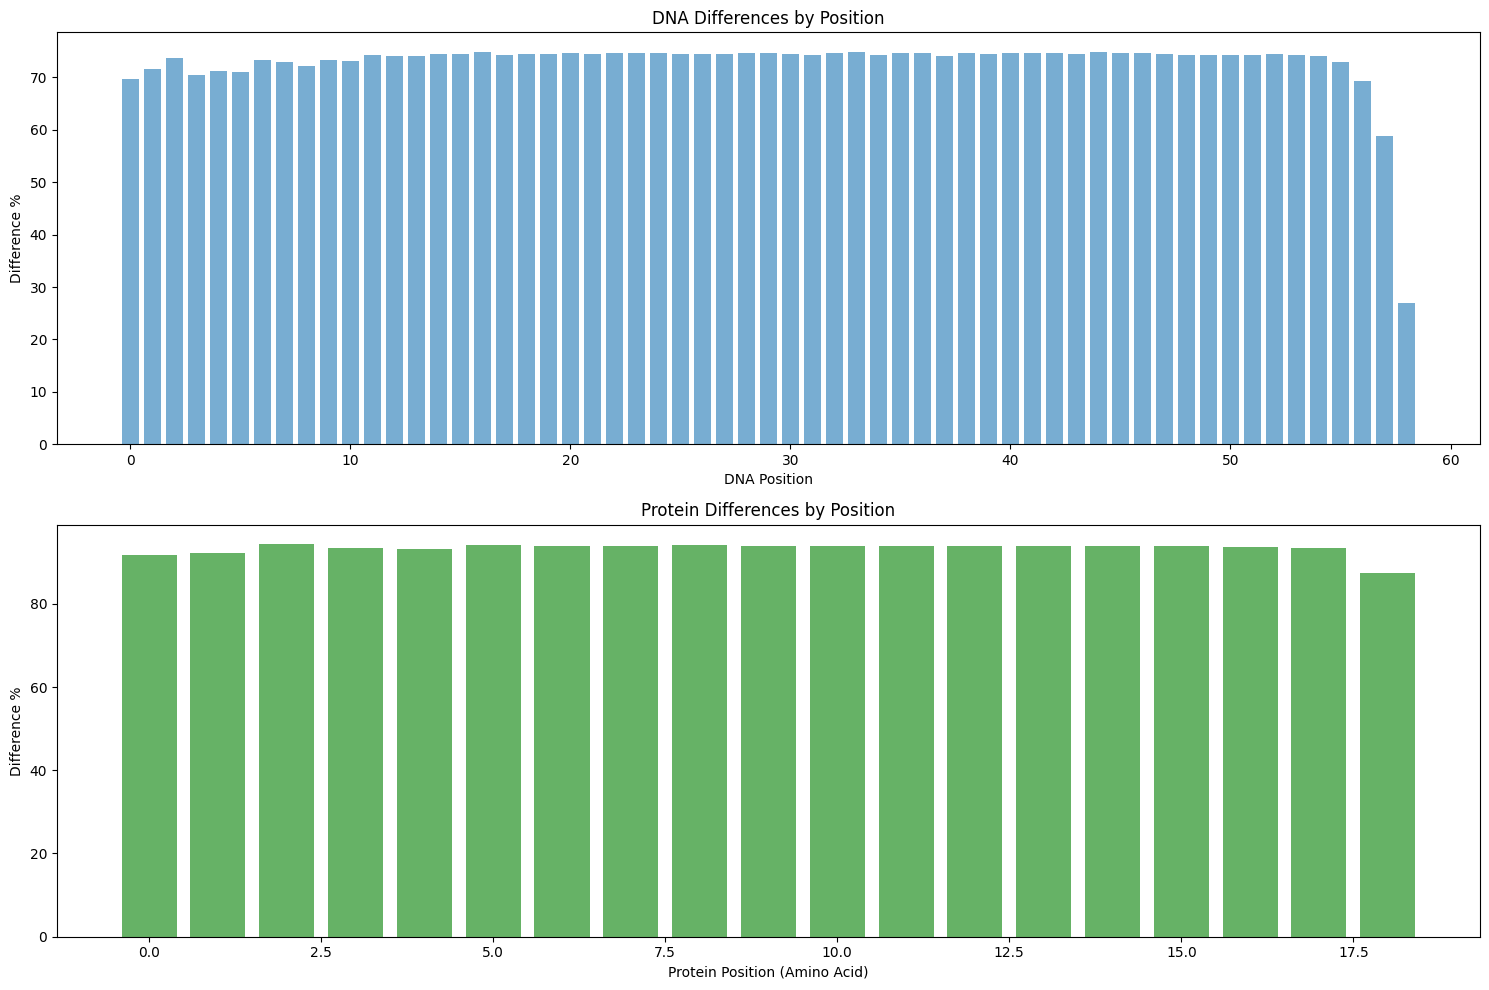

In [ ]:
#Agrin folder 1

results = compare_dna_and_protein(file1_path, file2_path)
plot_dna_protein_differences(results)


FASTQ Comparison Summary:
Total reads processed: 3,002,992

Sequence Differences:
- Different sequences: 1,467,231 (48.86%)
- Length differences: 1,535,749 (51.14%)

Quality Score Differences:
- Reads with different qualities: 1,077,161 (35.87%)

Missing Reads:
- Missing in file 1: 0
- Missing in file 2: 0

Top 10 positions with most sequence differences:
Position 33: 1,102,110 differences (36.70%)
Position 34: 1,096,959 differences (36.53%)
Position 17: 1,096,517 differences (36.51%)
Position 29: 1,095,952 differences (36.50%)
Position 18: 1,094,925 differences (36.46%)
Position 46: 1,094,225 differences (36.44%)
Position 22: 1,094,099 differences (36.43%)
Position 28: 1,093,803 differences (36.42%)
Position 16: 1,093,788 differences (36.42%)
Position 23: 1,093,481 differences (36.41%)

Top 10 positions with most quality differences:
Position 33: 144,703 differences (4.82%)
Position 3: 140,609 differences (4.68%)
Position 1: 137,763 differences (4.59%)
Position 46: 130,668 difference

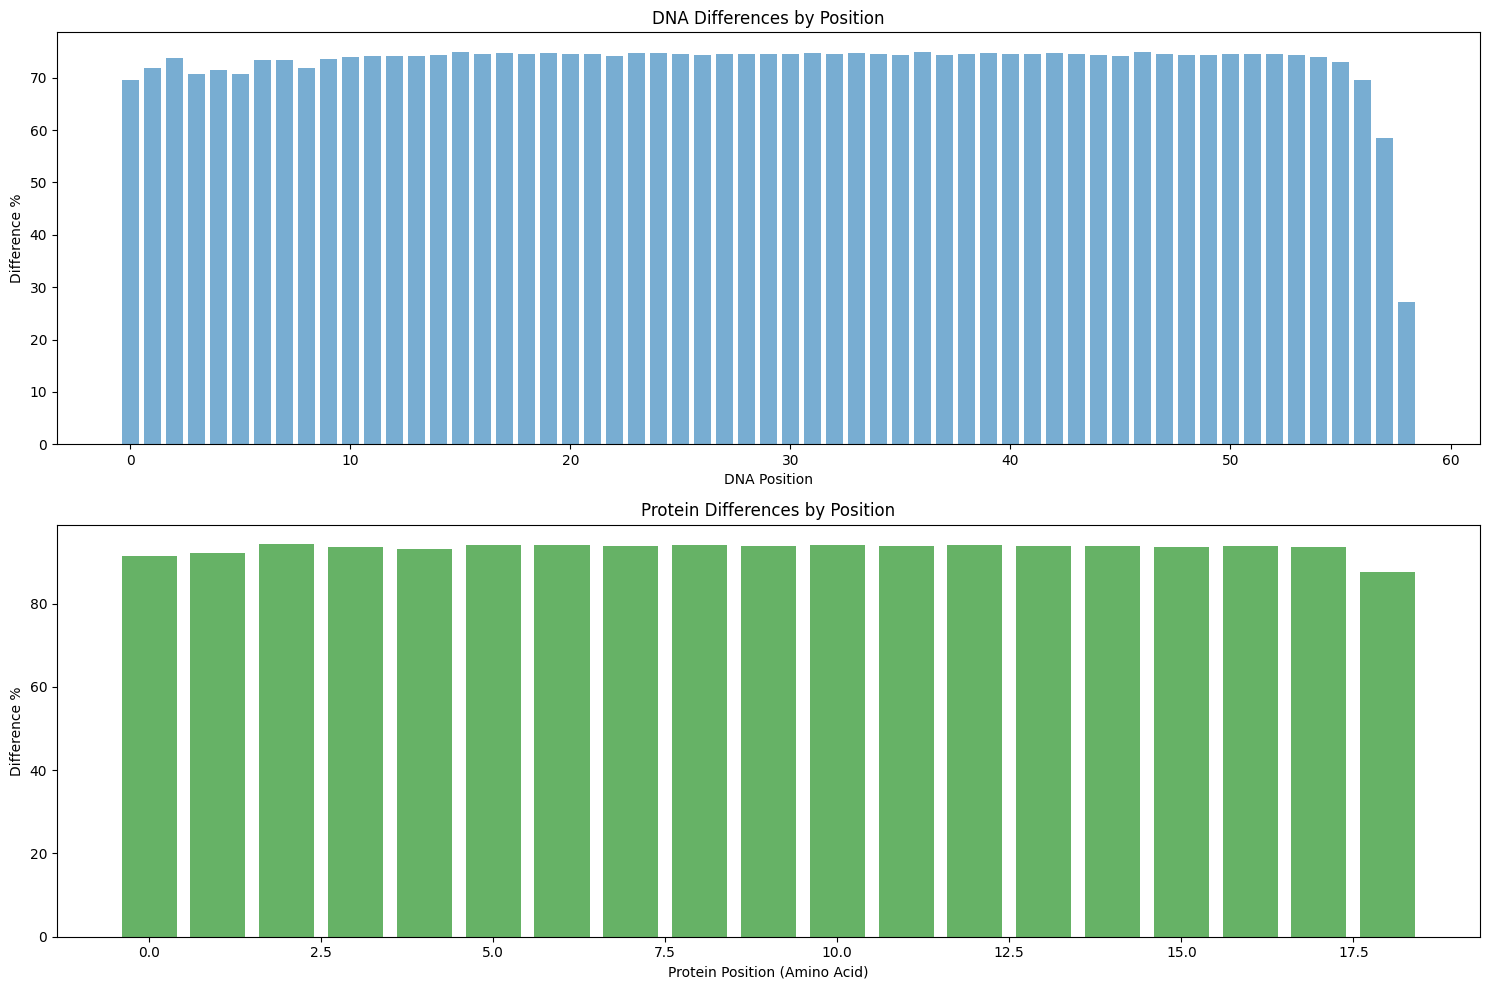

In [ ]:
#agrin folder 2

file1_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb0dd8a4/lib103915_S9_L002_R1_001.fastq.gz"
file2_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb0dd8a4/lib103915_S9_L002_R2_001.fastq.gz"

differences = compare_fastq_files(file1_path, file2_path)
print_comparison_summary(differences)
results = compare_dna_and_protein(file1_path, file2_path)
plot_dna_protein_differences(results)

In [ ]:
from Bio import SeqIO, Align
from Bio.Seq import Seq
from Bio.Align import substitution_matrices
import numpy as np
from difflib import SequenceMatcher

def compare_rna_sequences(ref_seq, mut_seq):
    """
    Compare reference and mutated RNA sequences using multiple methods

    Parameters:
    ref_seq (str): Reference RNA sequence
    mut_seq (str): Mutated RNA sequence

    Returns:
    dict: Results from different comparison methods
    """
    results = {}

    # Method 1: Using Biopython's pairwise aligner
    aligner = Align.PairwiseAligner()
    aligner.match_score = 2
    aligner.mismatch_score = -1
    aligner.open_gap_score = -0.5
    aligner.extend_gap_score = -0.1
    alignment = aligner.align(ref_seq, mut_seq)[0]

    # Calculate matches manually from the alignment
    matches = sum(1 for a, b in zip(alignment.target, alignment.query) if a == b)

    results['global_alignment'] = {
        'alignment': str(alignment),
        'score': alignment.score,
        'percent_identity': (matches / len(alignment.target)) * 100,
        'alignment_length': len(alignment.target)
    }

    # Method 2: Identify specific mutation positions
    mutations = []
    for i, (ref, mut) in enumerate(zip(ref_seq, mut_seq)):
        if ref != mut:
            mutations.append({
                'position': i + 1,
                'reference': ref,
                'mutation': mut
            })
    results['mutations'] = mutations

    # Method 3: Calculate sequence similarity ratio
    similarity = SequenceMatcher(None, ref_seq, mut_seq).ratio()
    results['similarity_ratio'] = similarity

    # Add detailed statistics
    results['statistics'] = {
        'sequence_length': len(ref_seq),
        'mutation_count': len(mutations),
        'mutation_rate': len(mutations) / len(ref_seq) if len(ref_seq) > 0 else 0
    }

    return results

# Example usage
def test_comparison():
    # Example with a single point mutation
    ref_sequence = "AUGCCGUUAAGGCUAGCUAGCUAGC"
    mut_sequence = "AUGCCGUUAAGGCUAGCUAGCUAGC".replace('U', 'C', 1)

    print("Comparing sequences:")
    print(f"Reference: {ref_sequence}")
    print(f"Mutated:   {mut_sequence}")
    print("\nResults:")

    results = compare_rna_sequences(ref_sequence, mut_sequence)

    # Print formatted results
    print("\nGlobal Alignment:")
    print(f"Score: {results['global_alignment']['score']:.2f}")
    print(f"Percent Identity: {results['global_alignment']['percent_identity']:.2f}%")
    print(f"Alignment:\n{results['global_alignment']['alignment']}")

    print("\nMutations:")
    for mut in results['mutations']:
        print(f"Position {mut['position']}: {mut['reference']} → {mut['mutation']}")

    print(f"\nOverall Similarity: {results['similarity_ratio']:.2%}")

    return results

# Uncomment to run the test
test_results = test_comparison()

Comparing sequences:
Reference: AUGCCGUUAAGGCUAGCUAGCUAGC
Mutated:   ACGCCGUUAAGGCUAGCUAGCUAGC

Results:

Global Alignment:
Score: 47.00
Percent Identity: 96.00%
Alignment:
target            0 AUGCCGUUAAGGCUAGCUAGCUAGC 25
                  0 |.||||||||||||||||||||||| 25
query             0 ACGCCGUUAAGGCUAGCUAGCUAGC 25


Mutations:
Position 2: U → C

Overall Similarity: 96.00%


In [ ]:
import gzip
import os
import glob
from pathlib import Path
import shutil
from concurrent.futures import ThreadPoolExecutor
from typing import List, Union

def unzip_fastq(
    input_path: Union[str, Path],
    output_dir: Union[str, Path] = None,
    delete_original: bool = False,
    verbose: bool = True
) -> str:
    """
    Unzip a single .gz FASTQ file.

    Args:
        input_path: Path to the .gz file
        output_dir: Directory to save unzipped file (default: same as input)
        delete_original: Whether to delete the original .gz file
        verbose: Whether to print progress

    Returns:
        Path to the unzipped file
    """
    input_path = Path(input_path)

    # Validate input file
    if not input_path.exists():
        raise FileNotFoundError(f"Input file not found: {input_path}")

    if not input_path.name.endswith('.gz'):
        raise ValueError(f"Input file must be .gz format: {input_path}")

    # Setup output path
    if output_dir is None:
        output_dir = input_path.parent
    else:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

    # Remove .gz extension for output filename
    output_path = output_dir / input_path.name.replace('.gz', '')

    if verbose:
        print(f"Unzipping: {input_path}")

    # Unzip the file
    with gzip.open(input_path, 'rb') as f_in:
        with open(output_path, 'wb') as f_out:
            shutil.copyfileobj(f_in, f_out)

    if delete_original:
        input_path.unlink()
        if verbose:
            print(f"Deleted original: {input_path}")

    if verbose:
        print(f"Completed: {output_path}")

    return str(output_path)

def batch_unzip_fastq(
    input_dir: Union[str, Path],
    pattern: str = "*.fastq.gz",
    output_dir: Union[str, Path] = None,
    delete_original: bool = False,
    max_workers: int = 4,
    verbose: bool = True
) -> List[str]:
    """
    Unzip multiple .gz FASTQ files in parallel.

    Args:
        input_dir: Directory containing .gz files
        pattern: Glob pattern to match files
        output_dir: Directory to save unzipped files (default: same as input)
        delete_original: Whether to delete original .gz files
        max_workers: Number of parallel workers
        verbose: Whether to print progress

    Returns:
        List of paths to unzipped files
    """
    input_dir = Path(input_dir)
    if not input_dir.exists():
        raise FileNotFoundError(f"Input directory not found: {input_dir}")

    # Get list of files to process
    gz_files = list(input_dir.glob(pattern))
    if not gz_files:
        raise FileNotFoundError(f"No files matching pattern '{pattern}' found in {input_dir}")

    if verbose:
        print(f"Found {len(gz_files)} files to unzip")

    # Process files in parallel
    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [
            executor.submit(
                unzip_fastq,
                gz_file,
                output_dir,
                delete_original,
                verbose
            )
            for gz_file in gz_files
        ]

        # Collect results
        output_files = [future.result() for future in futures]

    if verbose:
        print(f"Successfully unzipped {len(output_files)} files")

    return output_files

In [ ]:
# # Example usage
# if __name__ == "__main__":
#     # Single file
#     try:
#         unzipped_file = unzip_fastq(
#             "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb0dd8a4/lib103915_S9_L002_R2_001.fastq.gz",
#             delete_original=False
#         )
#         print(f"Unzipped file: {unzipped_file}")
#     except Exception as e:
#         print(f"Error processing single file: {e}")

#     # Multiple files
#     try:
#         unzipped_files = batch_unzip_fastq(
#             "path/to/your/directory",
#             pattern="*.fastq.gz",
#             max_workers=4,
#             delete_original=False
#         )
#         print(f"Unzipped {len(unzipped_files)} files")
#     except Exception as e:
#         print(f"Error processing batch: {e}")

In [ ]:
file1_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb0dd8a4/lib103915_S9_L002_R1_001.fastq"
file2_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb0dd8a4/lib103915_S9_L002_R2_001.fastq"

compare_rna_sequences(file1_path, file2_path)

{'global_alignment': {'alignment': 'target            0 /content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agri\n                  0 |||||||||||||||||||||||||||||||||||\nquery             0 /content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agri\n\ntarget           60 n Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb\n                 35 |\nquery            60 n Coating/Copy of lib103915_L2-ds.85e645e2ce164f339820ec34eb\n\ntarget          120 0dd8a4/lib103915_S9_L002_R1_001.fastq 157\n                 36 ||||||||||||||||||||||||||.||||||||||  73\nquery           120 0dd8a4/lib103915_S9_L002_R2_001.fastq 157\n',
  'score': 311.0,
  'percent_identity': 99.36305732484077,
  'alignment_length': 157},
 'mutations': [{'position': 147, 'reference': '1', 'mutation': '2'}],
 'similarity_ratio': 0.9936305732484076,
 'statistics': {'sequence_length': 157,
  'mutation_count': 1,
  'mutation_rate': 0.006369426751592357}}

In [ ]:
from Bio import SeqIO
from Bio import Align
from difflib import SequenceMatcher
from typing import Dict, List, Tuple
import gzip

def read_fastq_sequences(fastq_file: str, num_sequences: int = None) -> List[str]:
    """
    Read sequences from a FASTQ file.

    Args:
        fastq_file: Path to FASTQ file
        num_sequences: Number of sequences to read (None for all)

    Returns:
        List of sequences
    """
    sequences = []
    try:
        # Try reading as regular FASTQ first
        with open(fastq_file, 'r') as handle:
            for record in SeqIO.parse(handle, "fastq"):
                sequences.append(str(record.seq))
                if num_sequences and len(sequences) >= num_sequences:
                    break
    except UnicodeDecodeError:
        # If that fails, try reading as gzipped FASTQ
        with gzip.open(fastq_file, 'rt') as handle:
            for record in SeqIO.parse(handle, "fastq"):
                sequences.append(str(record.seq))
                if num_sequences and len(sequences) >= num_sequences:
                    break

    return sequences

def compare_fastq_files(file1: str, file2: str, num_sequences: int = 1000) -> Dict:
    """
    Compare sequences between two FASTQ files.

    Args:
        file1: Path to first FASTQ file
        file2: Path to second FASTQ file
        num_sequences: Number of sequences to compare

    Returns:
        Dictionary with comparison results
    """
    # Read sequences from both files
    sequences1 = read_fastq_sequences(file1, num_sequences)
    sequences2 = read_fastq_sequences(file2, num_sequences)

    if not sequences1 or not sequences2:
        raise ValueError("No sequences found in one or both files")

    # Initialize comparison results
    overall_results = {
        'num_sequences_compared': min(len(sequences1), len(sequences2)),
        'sequence_length': len(sequences1[0]),
        'average_identity': 0,
        'different_sequences': 0,
        'example_differences': [],
        'summary': {}
    }

    # Compare sequences
    total_identity = 0
    for i, (seq1, seq2) in enumerate(zip(sequences1, sequences2)):
        # Compare individual sequences
        aligner = Align.PairwiseAligner()
        aligner.match_score = 2
        aligner.mismatch_score = -1
        aligner.open_gap_score = -0.5
        aligner.extend_gap_score = -0.1

        alignment = aligner.align(seq1, seq2)[0]
        matches = sum(1 for a, b in zip(alignment.target, alignment.query) if a == b)
        identity = (matches / len(alignment.target)) * 100

        total_identity += identity

        # If sequences are different, store an example
        if identity < 100 and len(overall_results['example_differences']) < 5:
            overall_results['example_differences'].append({
                'sequence_pair': i + 1,
                'sequence1': seq1,
                'sequence2': seq2,
                'percent_identity': identity,
                'alignment': str(alignment)
            })
            overall_results['different_sequences'] += 1

    # Calculate summary statistics
    overall_results['average_identity'] = total_identity / overall_results['num_sequences_compared']
    overall_results['summary'] = {
        'total_sequences_compared': overall_results['num_sequences_compared'],
        'sequences_with_differences': overall_results['different_sequences'],
        'average_percent_identity': overall_results['average_identity'],
        'sequence_length': overall_results['sequence_length']
    }

    return overall_results

# Example usage
def compare_paired_end_reads(r1_file: str, r2_file: str, num_sequences: int = 1000):
    """
    Compare paired-end read files and print formatted results.
    """
    print(f"Comparing first {num_sequences} sequences from paired-end reads...")
    results = compare_fastq_files(r1_file, r2_file, num_sequences)

    print("\nSummary:")
    print(f"Total sequences compared: {results['summary']['total_sequences_compared']}")
    print(f"Sequences with differences: {results['summary']['sequences_with_differences']}")
    print(f"Average sequence identity: {results['summary']['average_percent_identity']:.2f}%")
    print(f"Sequence length: {results['summary']['sequence_length']} bp")

    if results['example_differences']:
        print("\nExample differences:")
        for i, diff in enumerate(results['example_differences'], 1):
            print(f"\nDifference Example {i}:")
            print(f"Sequence pair: {diff['sequence_pair']}")
            print(f"Identity: {diff['percent_identity']:.2f}%")
            print("Sequence 1:", diff['sequence1'][:50] + "..." if len(diff['sequence1']) > 50 else diff['sequence1'])
            print("Sequence 2:", diff['sequence2'][:50] + "..." if len(diff['sequence2']) > 50 else diff['sequence2'])

    return results

In [ ]:
compare_paired_end_reads(file1_path,file2_path, 100000)

Comparing first 100000 sequences from paired-end reads...

Summary:
Total sequences compared: 100000
Sequences with differences: 5
Average sequence identity: 25.79%
Sequence length: 59 bp

Example differences:

Difference Example 1:
Sequence pair: 1
Identity: 32.20%
Sequence 1: CTTTAGGCTAGATACAAAATTCACACAGGGAAAGGCACGGACTCTGGGGA...
Sequence 2: GTGCTGGACTTTGAACACTTTCTGCCCATGCTGCAGACAGTGGCCAAGAA...

Difference Example 2:
Sequence pair: 2
Identity: 18.64%
Sequence 1: CCCTGGATCTCCTCCCTTACCCTCCTCTGCTGGGAACCTAGCACACCTGA...
Sequence 2: TCTCTAAGGTGTCAAACTCCACAAAAGTTCAGAATCATGTCACTGGATCC...

Difference Example 3:
Sequence pair: 3
Identity: 31.03%
Sequence 1: ATATTGGAACTTATCCCTACGTTGCCACAATTAGATGGTCTGGAAAAATC...
Sequence 2: TATCTTTCCTGTTCTTAAAGGATCTAAAAAGAAGAAGAACTTCCTAACTG...

Difference Example 4:
Sequence pair: 4
Identity: 28.07%
Sequence 1: ATAATGAGGCTCTAGATTTAACAGAACTGATCAGTAATATGCCTAGCTTA...
Sequence 2: ATTCAATAGTTTGAAATCGTCCAGAGTCAGAAGCTGAGAGCTGGACAACA...

Difference Example 5:
Sequence pa

{'num_sequences_compared': 100000,
 'sequence_length': 59,
 'average_identity': 25.785142426403738,
 'different_sequences': 5,
 'example_differences': [{'sequence_pair': 1,
   'sequence1': 'CTTTAGGCTAGATACAAAATTCACACAGGGAAAGGCACGGACTCTGGGGAGACTGGGAA',
   'sequence2': 'GTGCTGGACTTTGAACACTTTCTGCCCATGCTGCAGACAGTGGCCAAGAACAAGGACCA',
   'percent_identity': 32.20338983050847,
   'alignment': 'target            0 ---CTTTAGG-C--TAGATACA--AAATT---CACACA-G--GGAAAGGCACGGAC--TC\n                  0 ---||---||-|--|-||-|||-----||---|-|-||-|--------|||--|||--|-\nquery             0 GTGCT---GGACTTT-GA-ACACT---TTCTGC-C-CATGCT------GCA--GACAGT-\n\ntarget           44 TGGG----GAGAC--TGGGA--A 59\n                 60 --||----||-||----|||--| 83\nquery            41 --GGCCAAGA-ACAA--GGACCA 59\n'},
  {'sequence_pair': 2,
   'sequence1': 'CCCTGGATCTCCTCCCTTACCCTCCTCTGCTGGGAACCTAGCACACCTGAATCAGCTGG',
   'sequence2': 'TCTCTAAGGTGTCAAACTCCACAAAAGTTCAGAATCATGTCACTGGATCCTGAGTCCAT',
   'percent_identity': 18.6440677

In [ ]:
file1_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/Copy of lib103907_L1-ds.913fa6af9c3744c78fb303355288cc60/lib103907_S1_L001_R1_001.fastq.gz"
file2_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/Copy of lib103907_L1-ds.913fa6af9c3744c78fb303355288cc60/lib103907_S1_L001_R1_001.fastq.gz"

compare_rna_sequences(file1_path, file2_path)

{'global_alignment': {'alignment': 'target            0 /content/drive/MyDrive/Schoolp/CSCI 474/Project Data/Copy of\n                  0 |||||||||||||||||||||||||||||||||||\nquery             0 /content/drive/MyDrive/Schoolp/CSCI 474/Project Data/Copy of\n\ntarget           60  lib103907_L1-ds.913fa6af9c3744c78fb303355288cc60/lib103907_\n                 35 \nquery            60  lib103907_L1-ds.913fa6af9c3744c78fb303355288cc60/lib103907_\n\ntarget          120 S1_L001_R1_001.fastq.gz 143\n                 35 |||||||||||||||||||||||  58\nquery           120 S1_L001_R1_001.fastq.gz 143\n',
  'score': 286.0,
  'percent_identity': 100.0,
  'alignment_length': 143},
 'mutations': [],
 'similarity_ratio': 1.0,
 'statistics': {'sequence_length': 143,
  'mutation_count': 0,
  'mutation_rate': 0.0}}

In [ ]:
compare_paired_end_reads(file1_path,file2_path, 3000000)

Comparing first 3000000 sequences from paired-end reads...

Summary:
Total sequences compared: 2169944
Sequences with differences: 0
Average sequence identity: 100.00%
Sequence length: 59 bp


{'num_sequences_compared': 2169944,
 'sequence_length': 59,
 'average_identity': 100.0,
 'different_sequences': 0,
 'example_differences': [],
 'summary': {'total_sequences_compared': 2169944,
  'sequences_with_differences': 0,
  'average_percent_identity': 100.0,
  'sequence_length': 59}}

In [ ]:
file1_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R1_001.fastq.gz"
file2_path = "/content/drive/MyDrive/Schoolp/CSCI 474/Project Data/01 Agrin Coating/Copy of lib103915_L1-ds.a783324d6d264b379cae47cc375dc63f/lib103915_S9_L001_R2_001.fastq.gz"

compare_paired_end_reads(file1_path, file2_path, 3000000)

Comparing first 3000000 sequences from paired-end reads...


KeyboardInterrupt: 